# Imports iniciais

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Carregamento e Análise (AED)

In [2]:
gym = pd.read_csv('data/gym_churn_us.csv')

display(gym.head()) # Primeiras linhas
print()
gym.info() # Informações básicas
print()
display(gym.describe().loc[['mean', 'std']]) # Informações numéricas
print()
display(gym.groupby('Churn').mean()) # Média por Churn
print()
print(f'Número de duplicatas: {gym.duplicated().sum()}') # Verifica se há duplicatas

,gender,Near_Location,Partner,Promo_friends,Phone,Contract_period,Group_visits,Age,Avg_additional_charges_total,Month_to_end_contract,Lifetime,Avg_class_frequency_total,Avg_class_frequency_current_month,Churn
0,1,1,1,1,0,6,1,29,14.227470,5.0,3,0.020398,0.000000,0
1,0,1,0,0,1,12,1,31,113.202938,12.0,7,1.922936,1.910244,0
2,0,1,1,0,1,1,0,28,129.448479,1.0,2,1.859098,1.736502,0
3,0,1,1,1,1,12,1,33,62.669863,12.0,2,3.205633,3.357215,0
4,1,1,1,1,1,1,0,26,198.362265,1.0,3,1.113884,1.120078,0



<class 'pandas.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 14 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   gender                             4000 non-null   int64  
 1   Near_Location                      4000 non-null   int64  
 2   Partner                            4000 non-null   int64  
 3   Promo_friends                      4000 non-null   int64  
 4   Phone                              4000 non-null   int64  
 5   Contract_period                    4000 non-null   int64  
 6   Group_visits                       4000 non-null   int64  
 7   Age                                4000 non-null   int64  
 8   Avg_additional_charges_total       4000 non-null   float64
 9   Month_to_end_contract              4000 non-null   float64
 10  Lifetime                           4000 non-null   int64  
 11  Avg_class_frequency_total          4000 non-null   float64
 12  Av

,gender,Near_Location,Partner,Promo_friends,Phone,Contract_period,Group_visits,Age,Avg_additional_charges_total,Month_to_end_contract,Lifetime,Avg_class_frequency_total,Avg_class_frequency_current_month,Churn
mean,0.510250,0.845250,0.486750,0.308500,0.903500,4.681250,0.412250,29.184250,146.943728,4.322750,3.724750,1.879020,1.767052,0.265250
std,0.499957,0.361711,0.499887,0.461932,0.295313,4.549706,0.492301,3.258367,96.355602,4.191297,3.749267,0.972245,1.052906,0.441521


,gender,Near_Location,Partner,Promo_friends,Phone,Contract_period,Group_visits,Age,Avg_additional_charges_total,Month_to_end_contract,Lifetime,Avg_class_frequency_total,Avg_class_frequency_current_month
Churn,,,,,,,,,,,,,
0,0.510037,0.873086,0.534195,0.353522,0.903709,5.747193,0.464103,29.976523,158.445715,5.283089,4.711807,2.024876,2.027882
1,0.510839,0.768143,0.355325,0.183789,0.902922,1.728558,0.268615,26.989632,115.082899,1.662582,0.990575,1.474995,1.044546



Número de duplicatas: 0


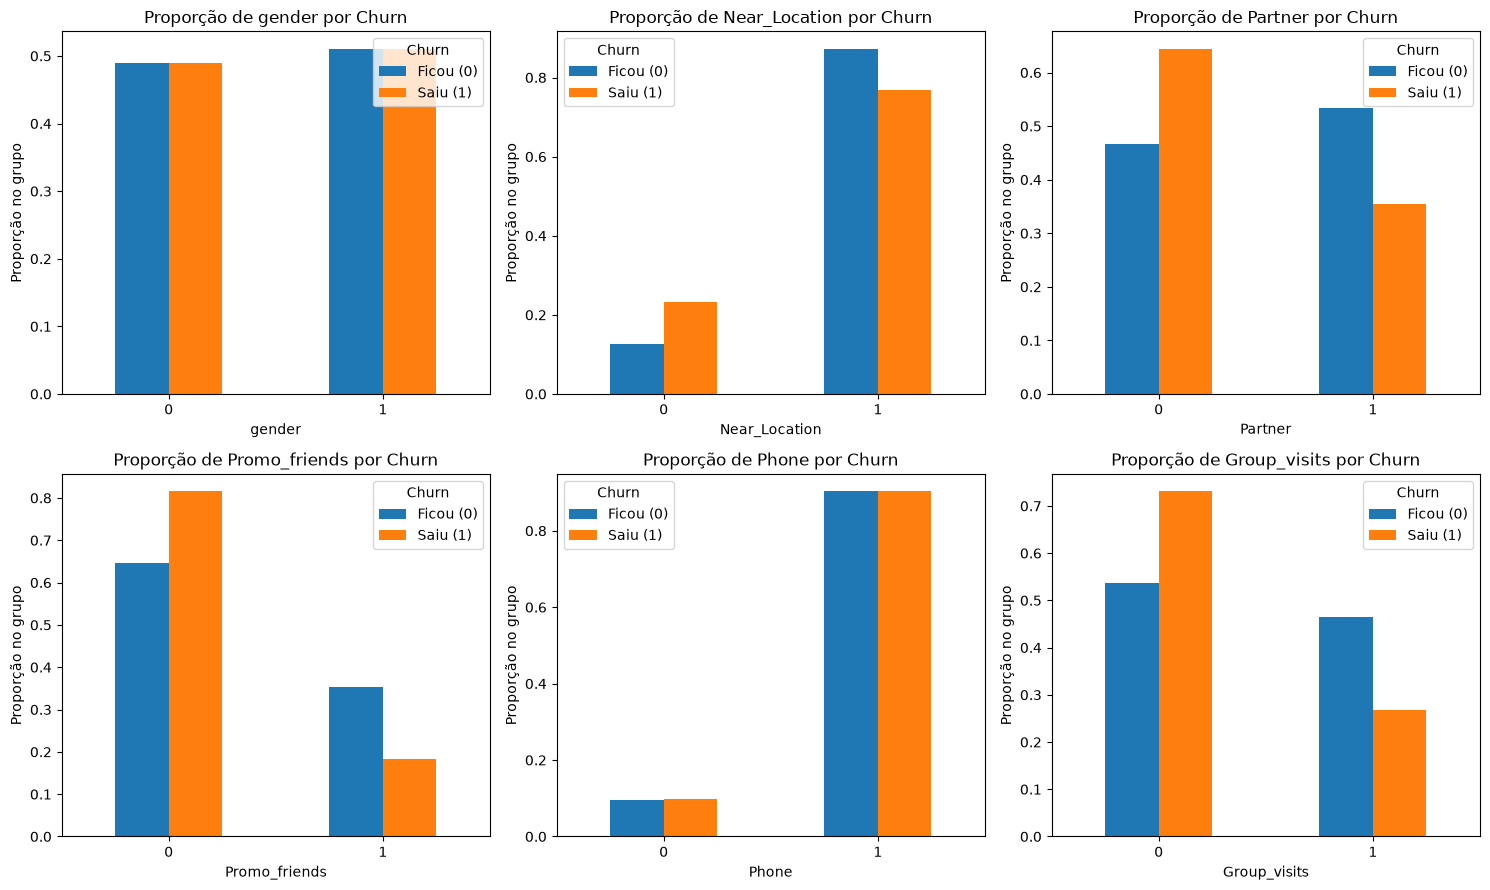

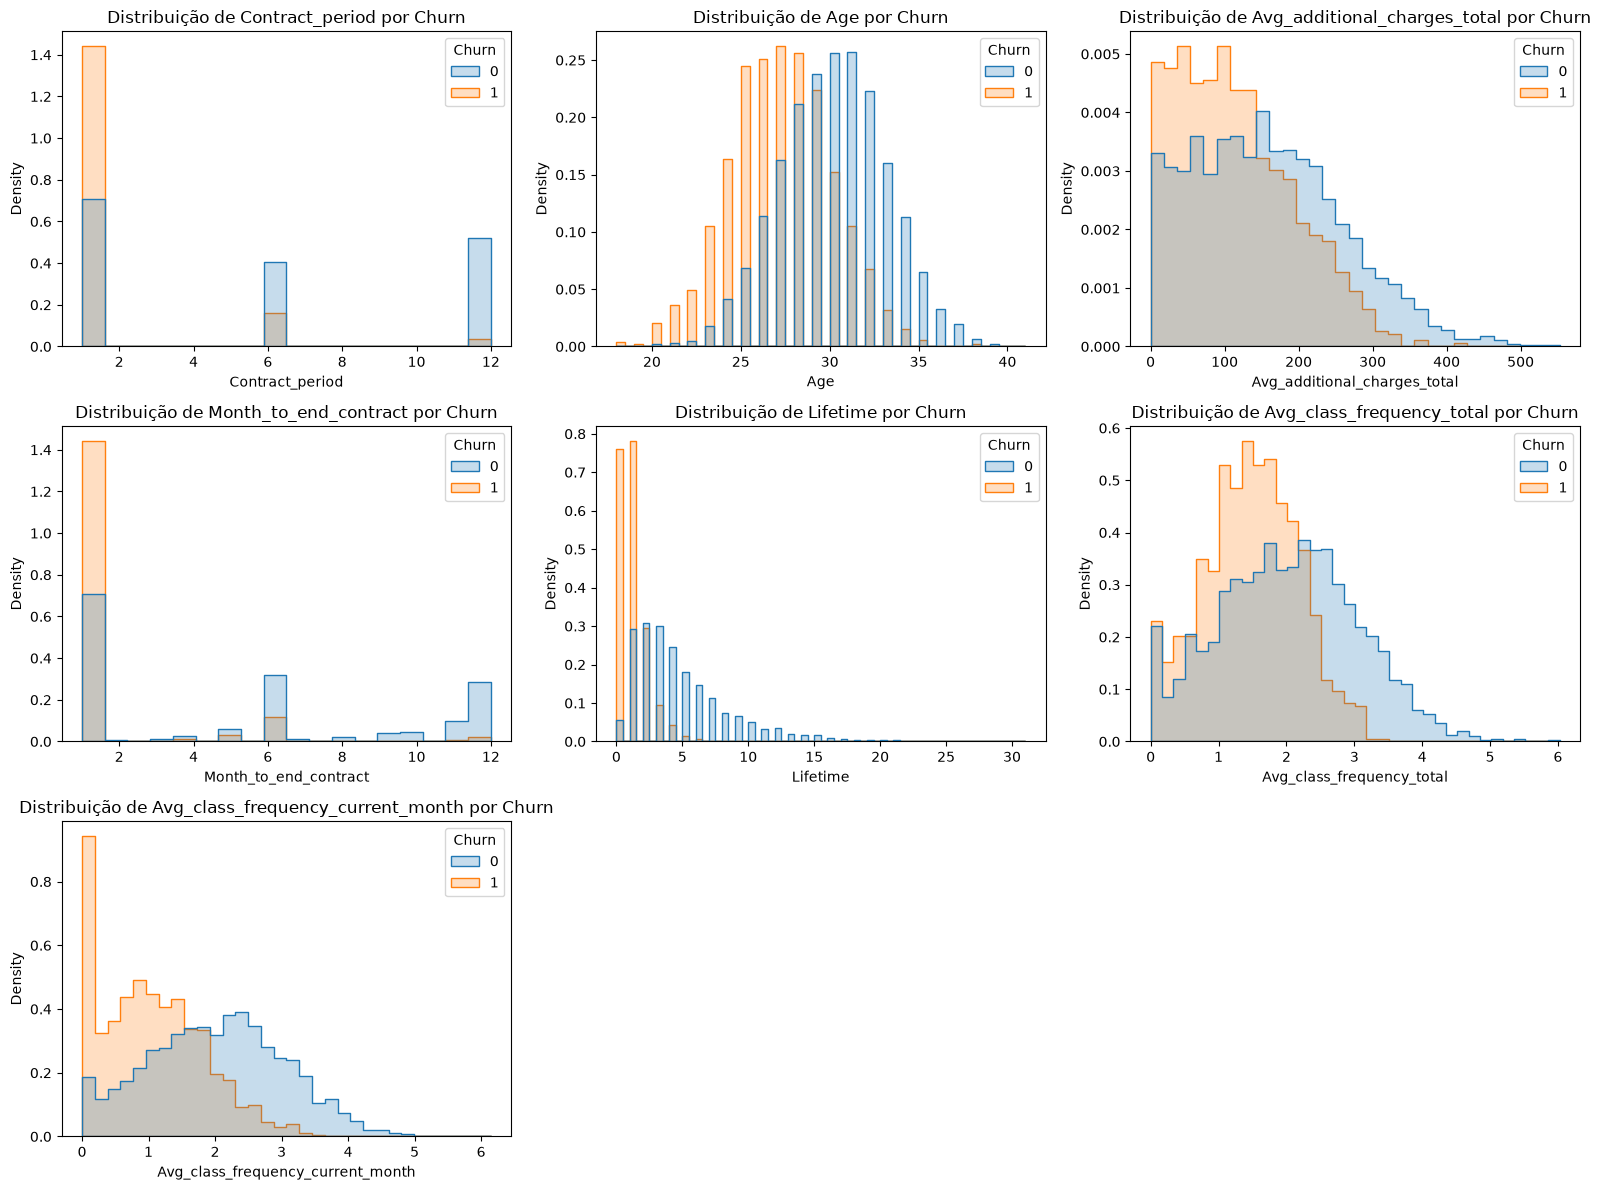

In [3]:
binary_cols = [
    'gender',
    'Near_Location',
    'Partner',
    'Promo_friends',
    'Phone',
    'Group_visits',
]
cont_cols = [
    'Contract_period',
    'Age',
    'Avg_additional_charges_total',
    'Month_to_end_contract',
    'Lifetime',
    'Avg_class_frequency_total',
    'Avg_class_frequency_current_month',
]

# Proporções das variáveis binárias dentro de cada grupo de Churn
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()

for i, col in enumerate(binary_cols):
  prop = pd.crosstab(gym[col], gym['Churn'], normalize='columns')
  prop.plot(kind='bar', ax=axes[i])
  axes[i].set_title(f'Proporção de {col} por Churn')
  axes[i].set_xlabel(col)
  axes[i].set_ylabel('Proporção no grupo')
  axes[i].legend(['Ficou (0)', 'Saiu (1)'], title='Churn')
  axes[i].tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.show()

# Distribuição das variáveis contínuas/numéricas por Churn (densidade normalizada por grupo)
fig, axes = plt.subplots(3, 3, figsize=(16, 12))
axes = axes.flatten()

for i, col in enumerate(cont_cols):
  sns.histplot(
      data=gym,
      x=col,
      hue='Churn',
      element='step',
      stat='density',
      common_norm=False,
      ax=axes[i],
  )
  axes[i].set_title(f'Distribuição de {col} por Churn')

for j in range(len(cont_cols), len(axes)):
  fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

O conjunto de dados da Model Fitness contém 4.000 registros e 14 colunas, sem valores ausentes. A taxa geral de rotatividade (`Churn`) do período analisado é de aproximadamente 26,5%.

A partir da comparação direta entre os grupos de clientes que permaneceram (`Churn = 0`) e os que cancelaram (`Churn = 1`), observam-se os seguintes padrões comportamentais associados à rotatividade:

* **Tempo de Contrato (`Contract_period`):** Clientes que cancelam apresentam médias menores de duração de contrato (~1,7 mês) em comparação aos que permanecem (~5,7 meses). Nos gráficos de distribuição, quem sai se concentra fortemente em contratos de 1 mês, enquanto quem fica tem maior presença de contratos de 6 e 12 meses.
* **Frequência de Visitas (`Avg_class_frequency_current_month`):** Há diferença entre as médias de frequência semanal no mês atual, com clientes que permanecem registrando cerca de 2,0 visitas por semana e aqueles que cancelam em torno de 1,0 visita por semana. A distribuição confirma que quem sai tende a se concentrar em frequências mais baixas (incluindo valores próximos de 0 a 1), enquanto quem permanece se desloca para frequências maiores.
* **Tempo de Vida na Academia (`Lifetime`):** Clientes com menor tempo de casa aparecem mais associados ao cancelamento, com média de *Lifetime* abaixo de 1 mês entre quem sai e acima de 4 meses entre quem permanece. A distribuição mostra forte concentração de quem cancela nos primeiros meses de adesão, com cauda longa à direita para clientes retidos.
* **Gastos Adicionais (`Avg_additional_charges_total`):** Clientes que permanecem apresentam média maior de gastos adicionais (~158,44) em relação aos que cancelam (~115,08). As distribuições são assimétricas à direita nos dois grupos, com sobreposição relevante, mas o grupo que permanece se estende mais para valores mais altos.
* **Variáveis Binárias (`Near_Location`, `Partner`, `Group_visits`, `Promo_friends`, `gender`, `Phone`):** Nas proporções por grupo, clientes que saem têm menor fração com `Near_Location = 1` (~76,8% vs. ~87,3% entre os que ficam), menor proporção de `Partner = 1` (~35,5% vs. ~53,4%), menor proporção de `Group_visits = 1` (~26,9% vs. ~46,4%) e menor proporção de `Promo_friends = 1` (~18,4% vs. ~35,4%). Já `gender` e `Phone` mantêm proporções muito semelhantes entre os dois grupos.

**Observação sobre os padrões nas distribuições:** De modo geral, as diferenças observadas nas médias se mantêm visíveis nas distribuições e proporções entre `Churn = 0` e `Churn = 1`, especialmente em `Contract_period`, `Lifetime`, frequência semanal recente, `Group_visits` e `Partner` — embora haja sobreposição considerável em variáveis contínuas como gastos adicionais e idade.

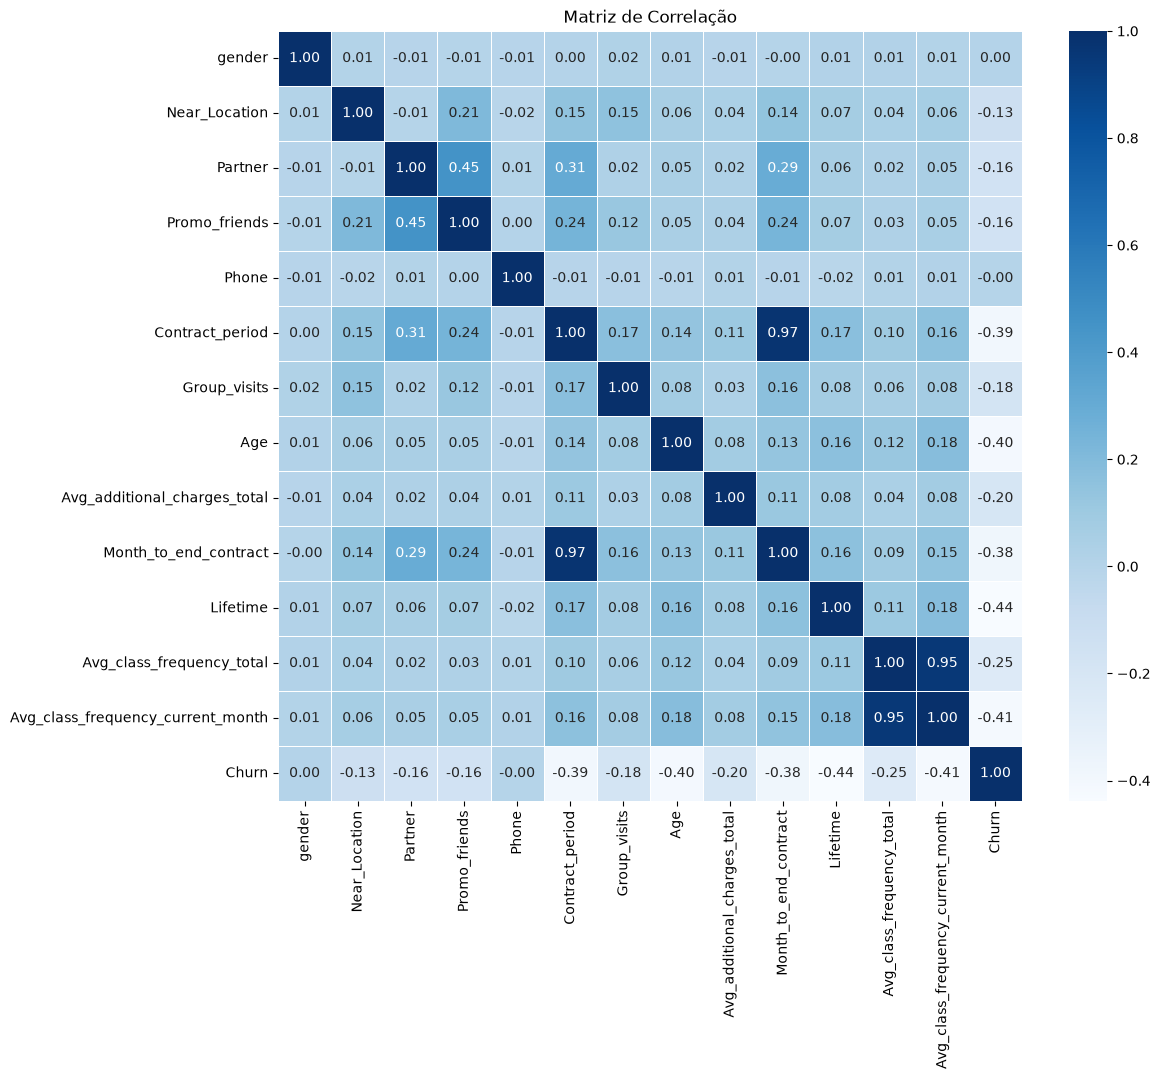

In [4]:
# Matriz de correlação
plt.figure(figsize=(12, 10))
sns.heatmap(gym.corr(), annot=True, fmt='.2f', cmap='Blues', linewidths=0.5)
plt.title('Matriz de Correlação')
plt.show()

## Conclusões da Matriz de Correlação

### Pares com Forte Correlação Positiva (Multicolinearidade)
* **`Contract_period` e `Month_to_end_contract` (0,97):** Apresentam correlação positiva muito alta, o que acompanha a relação esperada entre a duração do contrato e o tempo restante até o seu término.
* **`Avg_class_frequency_total` e `Avg_class_frequency_current_month` (0,95):** Também apresentam correlação positiva elevada, indicando que a frequência semanal no mês atual tende a acompanhar o histórico médio de frequência ao longo do tempo.

### Principais Fatores Associados ao Churn (Correlação Negativa)
* **`Lifetime` (-0,44):** Maior tempo de permanência na academia está associado a menor incidência de *churn*.
* **`Avg_class_frequency_current_month` (-0,41):** Maior frequência de visitas no mês atual está associada a menor ocorrência de *churn*.
* **`Age` (-0,40):** Idades maiores apresentam associação negativa com o *churn* neste conjunto de dados.
* **`Contract_period` (-0,39) e `Month_to_end_contract` (-0,38):** Contratos mais longos e maior tempo restante de contrato estão associados a menores taxas de *churn*.

# Imports para Machine Learning

In [5]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score
from sklearn.model_selection import train_test_split

# Aprendizado do modelo

In [6]:
# Separação das características e da variável objetivo
X = gym.drop('Churn', axis=1)
y = gym['Churn']

# Divisão dos dados de treinamento e validação
X_train, X_valid, y_train, y_valid = train_test_split(
    X, y, test_size=0.2, random_state=0
)

# Organização dos modelos com controle de aleatoriedade (seed)
models = {
    'RandomForestClassifier': RandomForestClassifier(random_state=0),
    'LogisticRegression': LogisticRegression(random_state=0, max_iter=1000),
}


# Função autossuficiente para teste dos modelos
def model_test(dc_model, X_train, y_train, X_test, y_test):
  for name, model in dc_model.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    print(f'Modelo usado: {name}')
    print(f'Acurácia: {accuracy_score(y_test, y_pred):.2f}')
    print(f'Precisão: {precision_score(y_test, y_pred):.2f}')
    print(f'Recall: {recall_score(y_test, y_pred):.2f}')
    print('-' * 35)

In [7]:
model_test(dc_model=models, X_train=X_train, y_train=y_train, X_test=X_valid, y_test=y_valid)

Modelo usado: RandomForestClassifier
Acurácia: 0.92
Precisão: 0.84
Recall: 0.82
-----------------------------------
Modelo usado: LogisticRegression
Acurácia: 0.93
Precisão: 0.86
Recall: 0.83
-----------------------------------


## Conclusão dos Modelos de Machine Learning

### Desempenho Geral dos Modelos
* **Regressão Logística:** Apresentou ligeira superioridade geral nos dados de validação, alcançando 93% de acurácia, 86% de precisão e 83% de sensibilidade (*recall*).
* **Floresta Aleatória:** Obteve resultados próximos e consistentes, registrando 92% de acurácia, 84% de precisão e 82% de *recall*.

### Análise das Métricas
* **Acurácia Alta (92%–93%):** Indica que a maior parte das classificações entre clientes que permanecem e clientes que saem está correta.
* **Equilíbrio entre Precisão e *Recall*:** O desempenho em *recall* (sensibilidade) é relevante neste cenário porque indica a capacidade do modelo de identificar clientes com risco de cancelamento (`Churn = 1`), apoiando ações preventivas de retenção.

### Escolha do Modelo
Com base nas métricas avaliadas no conjunto de validação, a **Regressão Logística** teve desempenho ligeiramente superior à Floresta Aleatória em acurácia, precisão e *recall*, podendo ser escolhida como modelo de referência para estimar o risco de rotatividade mensal. Com essas previsões, a equipe pode direcionar ações de retenção para os clientes com maior probabilidade de saída.

# Imports para o agrupamento

In [8]:
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

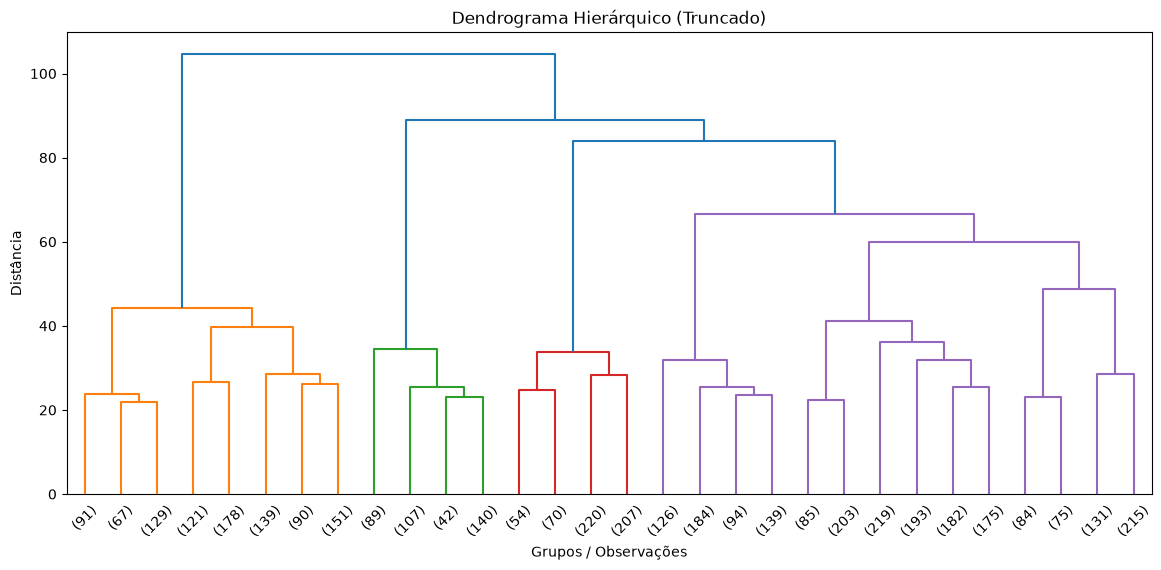

,gender,Near_Location,Partner,Promo_friends,Phone,Contract_period,Group_visits,Age,Avg_additional_charges_total,Month_to_end_contract,Lifetime,Avg_class_frequency_total,Avg_class_frequency_current_month,Churn
cluster_kr,,,,,,,,,,,,,,
0,0.486819,1.000000,0.243409,0.007030,0.899824,1.978910,0.326889,28.239016,130.877033,1.896309,2.477153,1.318003,1.083831,0.513181
1,0.592493,0.970509,0.288204,0.123324,0.898123,2.898123,0.482574,30.339142,164.193829,2.654155,5.219839,2.937411,2.944131,0.054960
2,0.499469,0.943677,0.740701,0.489904,0.900106,11.866100,0.551541,29.905420,165.146492,10.852285,4.737513,1.989423,1.980764,0.022317
3,0.483360,1.000000,0.798732,1.000000,0.911252,3.079239,0.445325,29.052298,139.858265,2.873217,3.510301,1.665722,1.547717,0.269414
4,0.496324,0.000000,0.466912,0.077206,0.915441,2.209559,0.215074,28.483456,133.630215,2.073529,2.781250,1.657657,1.466870,0.450368


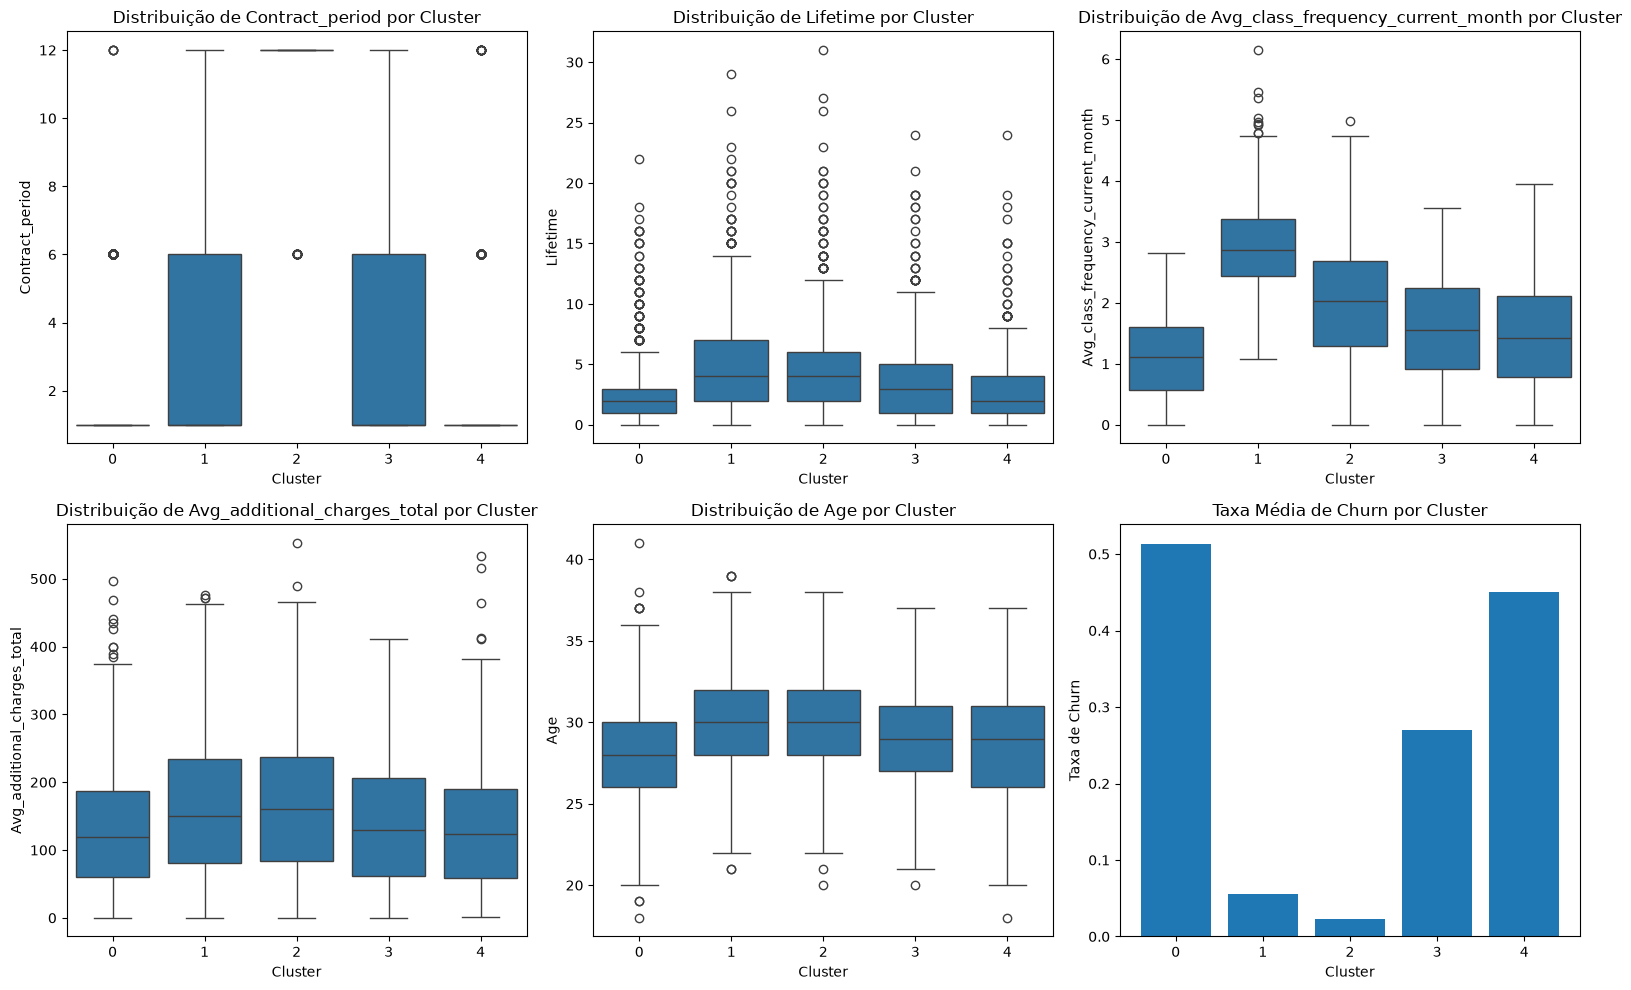

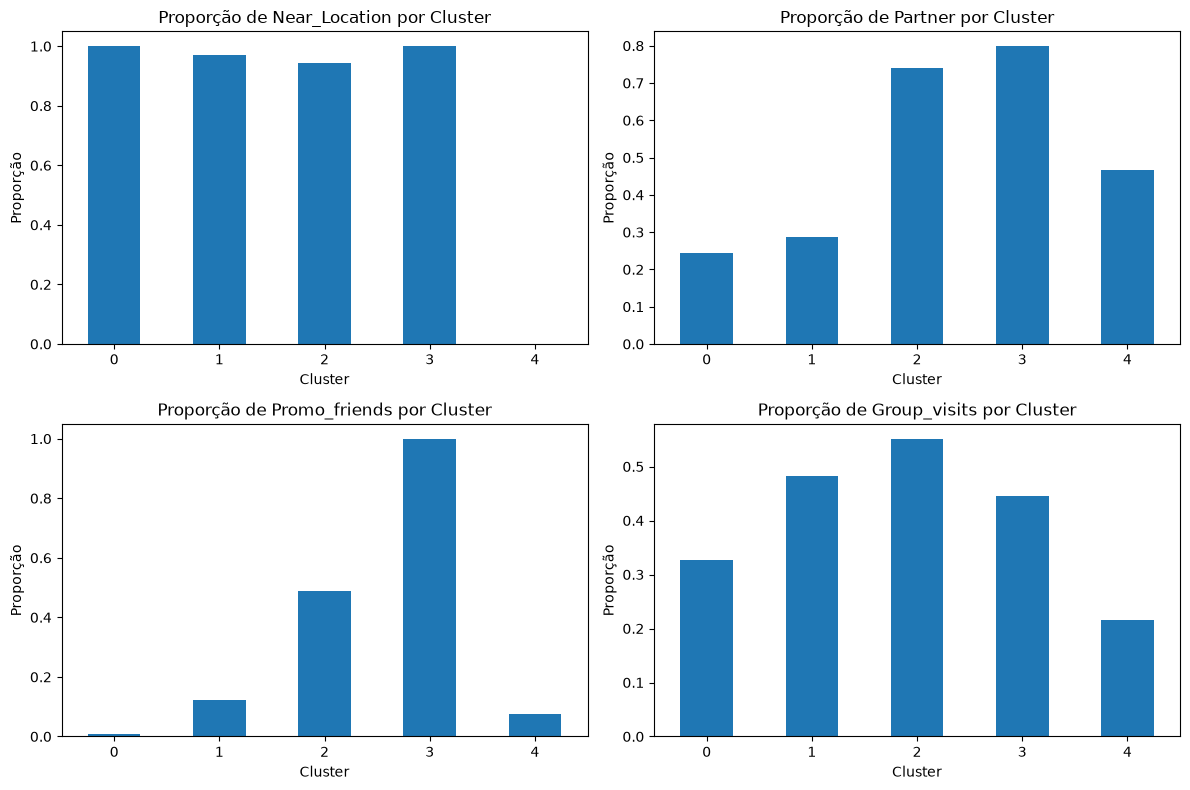

In [9]:
# 1. Padronização das features (excluindo Churn)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 2. Dendrograma hierárquico (truncado para evitar sobreposição de rótulos)
linked = linkage(X_scaled, method='ward')
plt.figure(figsize=(14, 6))
dendrogram(linked, truncate_mode='lastp', p=30)
plt.title('Dendrograma Hierárquico (Truncado)')
plt.xlabel('Grupos / Observações')
plt.ylabel('Distância')
plt.show()

# 3. Treinamento do K-Means e atribuição do cluster antes de qualquer plot/agrupamento
kmeans = KMeans(n_clusters=5, random_state=0)
labels = kmeans.fit_predict(X_scaled)
gym['cluster_kr'] = labels

# 4. Tabela de médias e taxa de churn por cluster
display(gym.groupby('cluster_kr').mean())

# 5. Boxplots para variáveis numéricas por cluster + taxa de churn
num_cols = [
    'Contract_period',
    'Lifetime',
    'Avg_class_frequency_current_month',
    'Avg_additional_charges_total',
    'Age',
]
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

for i, col in enumerate(num_cols):
  sns.boxplot(data=gym, x='cluster_kr', y=col, ax=axes[i])
  axes[i].set_title(f'Distribuição de {col} por Cluster')
  axes[i].set_xlabel('Cluster')

churn_cluster = gym.groupby('cluster_kr')['Churn'].mean()
axes[5].bar(churn_cluster.index.astype(str), churn_cluster.values)
axes[5].set_title('Taxa Média de Churn por Cluster')
axes[5].set_xlabel('Cluster')
axes[5].set_ylabel('Taxa de Churn')

plt.tight_layout()
plt.show()

# 6. Gráficos de barras (proporção) para variáveis binárias por cluster
bin_cols = ['Near_Location', 'Partner', 'Promo_friends', 'Group_visits']
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.flatten()

for i, col in enumerate(bin_cols):
  gym.groupby('cluster_kr')[col].mean().plot(kind='bar', ax=axes[i])
  axes[i].set_title(f'Proporção de {col} por Cluster')
  axes[i].set_xlabel('Cluster')
  axes[i].set_ylabel('Proporção')
  axes[i].tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.show()

## Conclusão do Agrupamento de Clientes (K-Means & Dendrograma)

A partir da padronização dos dados e da construção do dendrograma hierárquico, a leitura visual sugere **4 clusters** principais (correspondendo aos 4 ramos coloridos principais no corte padrão, feito em uma altura de distância elevada antes das fusões finais). Embora o dendrograma sozinho sugira 4 grupos, o número definido neste exercício foi $n = 5$ para padronizar a segmentação.

Com o **K-Means** ($n = 5$, `random_state = 0`) e a análise das distribuições e proporções por cluster:

* **Cluster 2 (churn ~2,2%):** Concentra contratos mais longos (mediana de 12 meses), alta proporção de empresas parceiras (~74,1%), participação em aulas em grupo (~55,2%) e gastos adicionais mais elevados em média (~165,15).
* **Cluster 1 (churn ~5,5%):** Destaca-se pela frequência semanal mais alta no mês atual (média ~2,94) e maior *Lifetime* médio (~5,22 meses), com alta presença em `Near_Location` (~97,1%) e aulas em grupo (~48,3%).
* **Cluster 3 (churn ~26,9%):** Reúne 100% de clientes vindos de `Promo_friends` e alta proporção de `Partner` (~79,9%), com *Near_Location = 1` e frequência semanal moderada (média ~1,55).
* **Cluster 4 (churn ~45,0%):** Caracteriza-se por `Near_Location = 0` em todo o grupo, menor participação em aulas coletivas (~21,5%) e contratos curtos.
* **Cluster 0 (churn ~51,3%):** Combina `Near_Location = 1` com contratos curtos, menor frequência semanal no mês atual (média ~1,08), menor *Lifetime* médio (~2,48 meses) e baixa presença de `Partner` (~24,3%) e `Promo_friends` (~0,7%).

# Perfil dos Agrupamentos (Clusters)
* **Cluster 2 — Os Clientes Mais Fiéis (Churn: 2,2%):**
  * **Características:** Possuem contratos médios mais longos (~11,9 meses), alta proporção de vínculo com empresas parceiras (~74%), participação relevante em aulas em grupo (~55%) e gastos adicionais médios (~165,15) entre os mais altos da base (com sobreposição visível nas distribuições). A frequência semanal média fica perto de 2 visitas, mas com dispersão ampla nos gráficos por cluster.
  * **Status:** Baixa rotatividade associada a contratos mais longos e maior engajamento.

* **Cluster 1 — Os Frequentadores Assíduos (Churn: 5,5%):**
  * **Características:** Apresentam a maior frequência semanal média no mês atual (~2,94 visitas/semana) e maior tempo médio de vida na academia (*Lifetime* ~5,22 meses), além de gastos adicionais médios (~164,19) próximos aos do Cluster 2. Mesmo com contratos médios mais curtos (~2,9 meses), o grupo apresenta baixa rotatividade.
  * **Status:** Alta frequência e maior tempo de casa associados a baixa rotatividade.

* **Cluster 3 — O Grupo Intermediário / Indicados (Churn: 26,9%):**
  * **Características:** Cerca de 100% entraram pela promoção *"Traga um amigo"* (`Promo_friends`) e ~80% têm vínculo com empresas parceiras, com proximidade à academia (`Near_Location` próximo de 1,0). Apresentam frequência semanal moderada (~1,55 visita/semana no mês atual) e contratos médios de cerca de 3 meses.
  * **Status:** Rotatividade moderada, próxima à média geral da academia.

* **Cluster 4 — Os Distantes / Desengajados (Churn: 45,0%):**
  * **Características:** Nenhum cliente do grupo mora ou trabalha perto da academia (`Near_Location = 0`), com menor participação em aulas coletivas (~21,5%) e contratos médios mais curtos (~2,2 meses).
  * **Status:** Rotatividade elevada associada à maior distância e menor participação em atividades em grupo.

* **Cluster 0 — O Grupo Crítico / Mais Propenso a Sair (Churn: 51,3%):**
  * **Características:** Apesar de morarem ou trabalharem perto da academia (`Near_Location = 1`), apresentam contratos médios curtos (~2,0 meses), menor frequência semanal média no mês atual (~1,08 visita/semana), menor *Lifetime* médio (~2,5 meses) e gastos adicionais médios mais baixos (~130,88).
  * **Status:** Rotatividade mais elevada entre os clusters, associada a menor frequência e menor tempo de permanência.

### Recomendações Estratégicas de Retenção

Com base nos padrões encontrados na AED, nos modelos preditivos e nos agrupamentos, sugerem-se as seguintes ações para a **Model Fitness**:

1. **Incentivar a Migração para Planos Longos (Foco nos Clusters 0 e 4):**
   * Oferecer descontos progressivos ou benefícios extras (como avaliação física gratuita ou vouchers para serviços internos) para alunos de planos mensais e trimestrais migrarem para planos semestrais ou anuais, aproximando-os do perfil de retenção observado no **Cluster 2**.

2. **Monitoramento Ativo de Frequência (Alerta Precoce):**
   * Utilizar o modelo de Regressão Logística para monitorar clientes cuja frequência semanal cair para **1 visita ou menos por semana** (principal característica do **Cluster 0**). Disparar mensagens personalizadas, convites para aulas experimentais ou sessões de acompanhamento com instrutores nos primeiros dois meses (*Lifetime* inicial).

3. **Fomentar o Engajamento em Aulas Coletivas e Ecossistema:**
   * Clientes que participam de aulas em grupo e consomem serviços adicionais apresentam menor taxa de cancelamento. Criar campanhas de boas-vindas que incluam aulas coletivas gratuitas no primeiro mês para fortalecer o vínculo com a academia, especialmente para clientes que não moram tão perto (**Cluster 4**).

4. **Qualificar Parcerias Corporativas (`Partner`) e Otimizar o Programa "Traga um Amigo" (`Promo_friends`):**
   * Embora tanto o **Cluster 2** (~74%) quanto o **Cluster 3** (~80%) tenham alta participação de clientes vindos de empresas parceiras, apenas o **Cluster 2** apresenta contratos longos (~11,9 meses) e baixíssima rotatividade (~2,2%), enquanto o **Cluster 3** possui contratos médios de cerca de 3 meses e rotatividade moderada (~26,9%). Assim, a equipe comercial deve não apenas expandir convênios com empresas da vizinhança, mas vincular os benefícios corporativos à contratação de planos mais longos.
   * **Ação complementar para indicações:** Como o **Cluster 3** é formado integralmente por clientes vindos da promoção *"Traga um amigo"* (`Promo_friends`) e apresenta churn próximo da média geral, vale criar incentivos de renovação em dupla (bônus se ambos renovarem após os primeiros 3 meses) para elevar a retenção desse grupo.